In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
from keras.layers import Dense, Dropout, LSTM,GRU,RNN,Embedding
from tensorflow.keras.utils import to_categorical
from keras.models import Sequential
from keras.preprocessing.sequence import pad_sequences
from keras.callbacks import EarlyStopping,ModelCheckpoint,TensorBoard
import matplotlib.pyplot as plt

In [2]:
(train_X,train_y),(test_X,test_Y)  = tf.keras.datasets.imdb.load_data()

In [3]:
train_X.shape

(25000,)

In [4]:
print(train_X)

[list([1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 22665, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 21631, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 19193, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 10311, 8, 4, 107, 117, 5952, 15, 256, 4, 31050, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 12118, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32])
 list([1, 194, 1153, 194, 825

In [5]:
train_y

array([1, 0, 0, ..., 0, 1, 0], dtype=int64)

In [6]:
X_train= pad_sequences(train_X,maxlen=100)
X_test = pad_sequences(test_X,maxlen=100)

In [10]:
vocab = 500000
embed_size = 128

In [ ]:
X_train.shape

(25000, 100)

In [12]:
model = Sequential()

model.add(Embedding(vocab,embed_size,input_shape=(X_train.shape[1],)))
model.add(GRU(units=64,activation='tanh'))
model.add(Dense(units=1,activation='sigmoid'))

In [13]:
model.compile(optimizer='SGD',loss="binary_crossentropy",metrics=['accuracy'])
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding (Embedding)       (None, 100, 128)          64000000  
                                                                 
 gru (GRU)                   (None, 64)                37248     
                                                                 
 dense (Dense)               (None, 1)                 65        
                                                                 
Total params: 64,037,313
Trainable params: 64,037,313
Non-trainable params: 0
_________________________________________________________________


In [ ]:
early = EarlyStopping(patience=3,monitor='val_loss')

In [15]:
history = model.fit(X_train,train_y,validation_data=(X_test,test_Y),callbacks=[early],epochs=10)

Epoch 1/10
782/782 [==============================] - 51s 61ms/step - loss: 0.6933 - accuracy: 0.4948 - val_loss: 0.6929 - val_accuracy: 0.5076
Epoch 2/10
782/782 [==============================] - 52s 67ms/step - loss: 0.6928 - accuracy: 0.5127 - val_loss: 0.6926 - val_accuracy: 0.5097
Epoch 3/10
782/782 [==============================] - 59s 76ms/step - loss: 0.6924 - accuracy: 0.5273 - val_loss: 0.6920 - val_accuracy: 0.5457
Epoch 4/10
782/782 [==============================] - 59s 75ms/step - loss: 0.6918 - accuracy: 0.5367 - val_loss: 0.6916 - val_accuracy: 0.5520
Epoch 5/10
782/782 [==============================] - 78s 100ms/step - loss: 0.6913 - accuracy: 0.5496 - val_loss: 0.6911 - val_accuracy: 0.5597
Epoch 6/10
782/782 [==============================] - 70s 90ms/step - loss: 0.6907 - accuracy: 0.5533 - val_loss: 0.6905 - val_accuracy: 0.5531
Epoch 7/10
782/782 [==============================] - 72s 92ms/step - loss: 0.6901 - accuracy: 0.5566 - val_loss: 0.6899 - val_accuracy

In [16]:
test_acc,test_los = model.evaluate(X_test,test_Y)

print("test_loss",test_acc*100)
print("test_acc",test_los*100)

782/782 [==============================] - 12s 15ms/step - loss: 0.6873 - accuracy: 0.5796
test_loss 68.7326967716217
test_acc 57.95599818229675


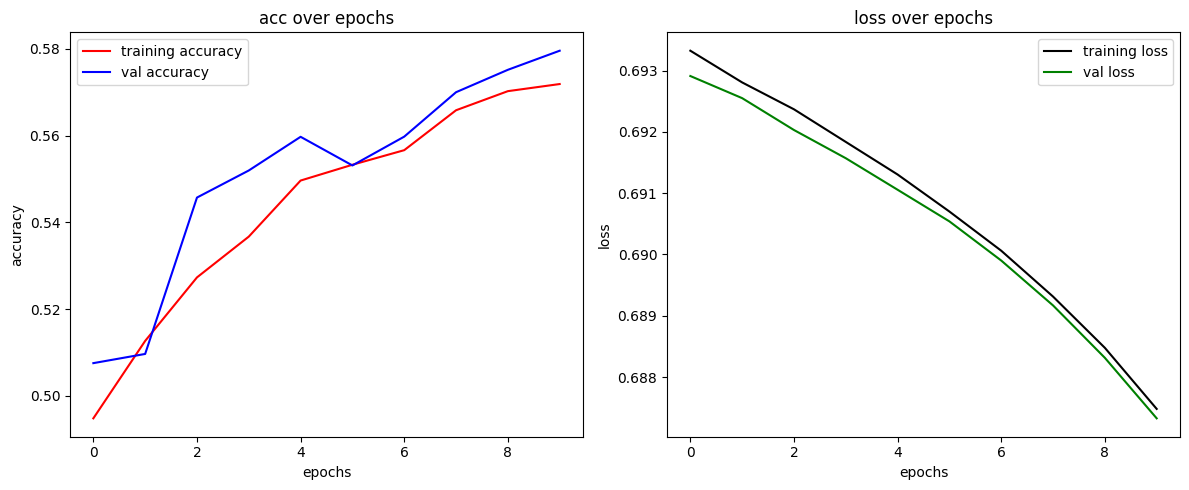

In [17]:
fig,axes = plt.subplots(1,2,figsize=(12,5))

axes[0].plot(history.history["accuracy"],color='red',label="training accuracy")
axes[0].plot(history.history["val_accuracy"],color='blue',label='val accuracy')
axes[0].set_title("acc over epochs")
axes[0].set_xlabel("epochs")
axes[0].set_ylabel("accuracy")
axes[0].legend()


axes[1].plot(history.history["loss"],color='black',label="training loss")
axes[1].plot(history.history["val_loss"],color='green',label='val loss')
axes[1].set_title("loss over epochs")
axes[1].set_xlabel("epochs")
axes[1].set_ylabel("loss")
axes[1].legend()


plt.tight_layout()
plt.show()